# Steel Surface Defect Inspection: OpenCV baseline vs YOLOv8
**Dataset:** NEU Surface Defect Database (6 defect types, 1,800 grayscale images)
**Goal:** classify surface defects, compare a classical OpenCV + Random Forest baseline with a YOLOv8 classifier, and report honest metrics.


## 1. Setup

In [1]:
!pip -q install ultralytics kagglehub

In [2]:
import os, re, glob, shutil, time, hashlib, random, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
WORK = "/content"
print("OpenCV", cv2.__version__)

OpenCV 4.14.0


In [3]:
RAW_DIR = None
try:
    import kagglehub
    RAW_DIR = kagglehub.dataset_download("kaustubhdikshit/neu-surface-defect-database")
    print("Downloaded to:", RAW_DIR)
except Exception as e:
    print("Automatic download failed:", repr(e)[:200])
    print("Run the next cell and upload the ZIP file manually.")

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Downloaded to: /kaggle/input/neu-surface-defect-database


In [4]:
# Run this cell ONLY if the automatic download above failed.
if RAW_DIR is None:
    from google.colab import files
    up = files.upload()                      # choose the dataset ZIP
    zip_name = list(up.keys())[0]
    RAW_DIR = f"{WORK}/neu_raw"
    os.makedirs(RAW_DIR, exist_ok=True)
    shutil.unpack_archive(zip_name, RAW_DIR)
    print("Extracted to:", RAW_DIR)
else:
    print("Dataset already available, skipping upload.")

Dataset already available, skipping upload.


## 3. Index the images
The class comes from the file name (for example `crazing_12.jpg` or `Cr_12.bmp`). Duplicate files are removed by content hash.

In [5]:
EXT = {".jpg", ".jpeg", ".bmp", ".png"}
CLASS_MAP = {
    "cr": "crazing", "crazing": "crazing",
    "in": "inclusion", "inclusion": "inclusion",
    "pa": "patches", "patches": "patches",
    "ps": "pitted_surface", "pitted": "pitted_surface", "pitted_surface": "pitted_surface",
    "rs": "rolled-in_scale", "rolled-in": "rolled-in_scale", "rolled-in_scale": "rolled-in_scale",
    "sc": "scratches", "scratches": "scratches",
}
def label_from_path(p):
    stem = os.path.splitext(os.path.basename(p))[0].lower()
    stem = re.sub(r"[_\-\s]*\d+$", "", stem)          # drop trailing number
    if stem in CLASS_MAP: return CLASS_MAP[stem]
    parent = os.path.basename(os.path.dirname(p)).lower()
    return CLASS_MAP.get(parent)

rows, seen = [], set()
for root, _, fnames in os.walk(RAW_DIR):
    for f in sorted(fnames):
        if os.path.splitext(f)[1].lower() not in EXT: continue
        p = os.path.join(root, f)
        lab = label_from_path(p)
        if lab is None: continue
        h = hashlib.md5(open(p, "rb").read()).hexdigest()
        if h in seen: continue
        seen.add(h)
        rows.append({"path": p, "label": lab})
df = pd.DataFrame(rows)
print("Images found:", len(df))
df["label"].value_counts()

Images found: 1799


,count
label,
inclusion,300
scratches,300
pitted_surface,300
crazing,300
rolled-in_scale,300
patches,299


## 4. Explore the data

Image sizes (sample): {(200, 200): 200}


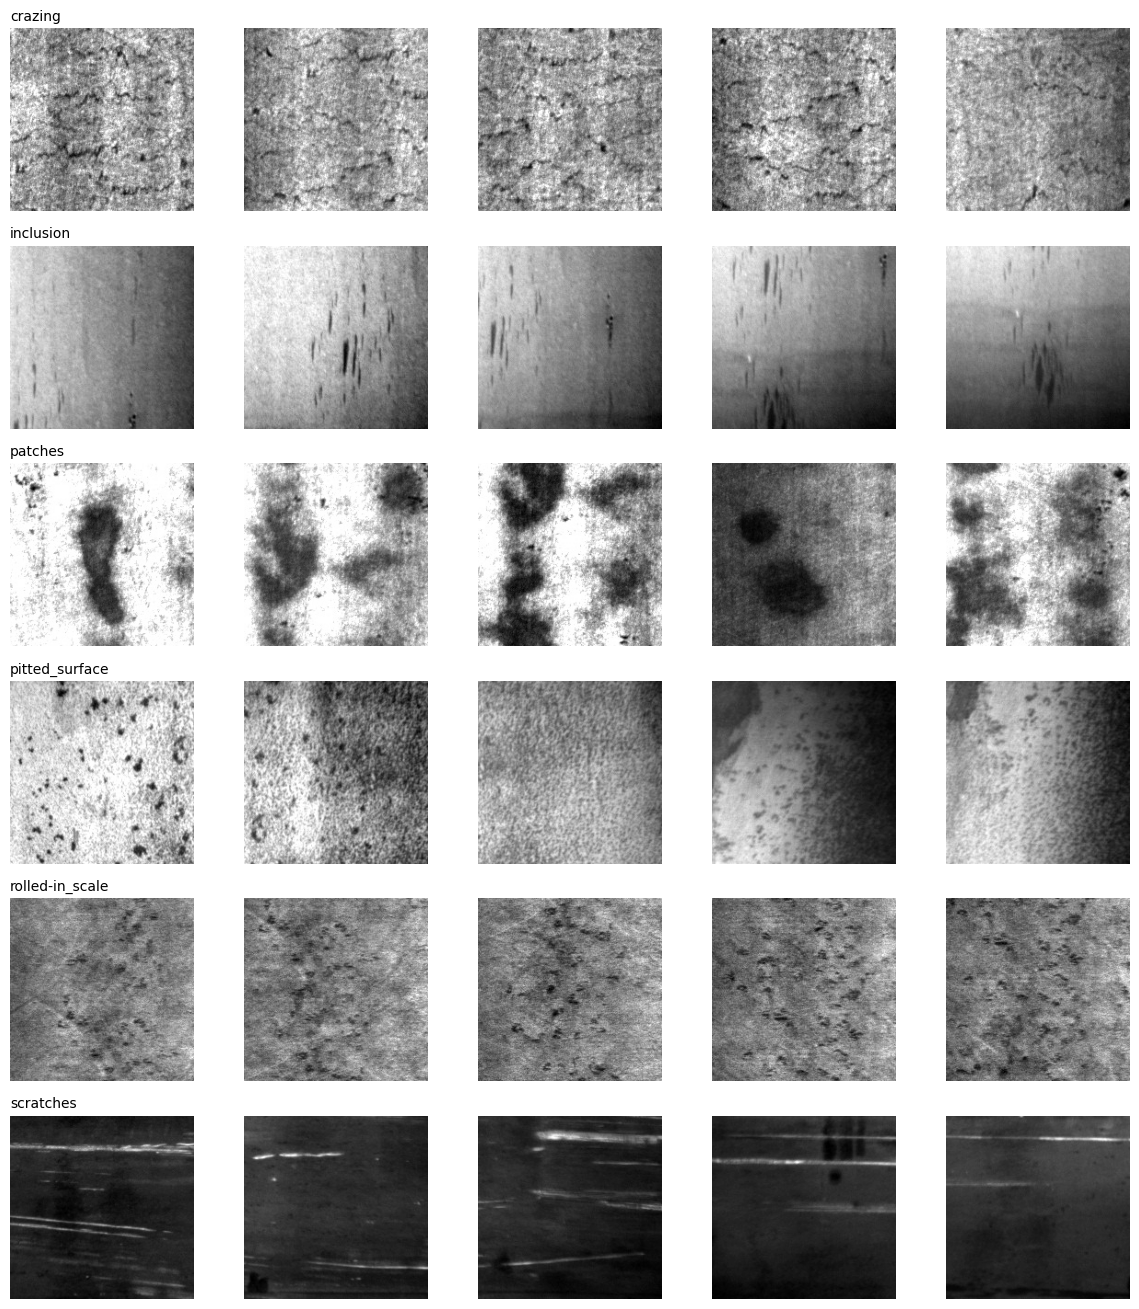

In [6]:
sizes = []
for p in df["path"].sample(min(200, len(df)), random_state=SEED):
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    sizes.append(im.shape)
print("Image sizes (sample):", pd.Series(sizes).value_counts().to_dict())

classes = sorted(df["label"].unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.2 * len(classes)))
for i, c in enumerate(classes):
    for j, p in enumerate(df[df.label == c]["path"].head(5)):
        axes[i, j].imshow(cv2.imread(p, 0), cmap="gray"); axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Train / validation / test split (stratified 70 / 15 / 15)

In [7]:
train_df, tmp = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp["label"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

DATA = f"{WORK}/neu_cls"
if os.path.exists(DATA): shutil.rmtree(DATA)
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for i, r in enumerate(part.itertuples()):
        ext = os.path.splitext(r.path)[1]
        dst = f"{DATA}/{name}/{r.label}"
        os.makedirs(dst, exist_ok=True)
        shutil.copy(r.path, f"{dst}/{i}{ext}")
print("YOLO folder ready:", DATA)

1259 270 270
YOLO folder ready: /content/neu_cls


## 6. Baseline: classical OpenCV features + Random Forest
We extract hand-made features (filters, edges, contours, histogram) with OpenCV, then train a simple classifier.

In [8]:
def extract_features(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (200, 200))
    blur = cv2.GaussianBlur(img, (5, 5), 0)
    gx = cv2.Sobel(blur, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(blur, cv2.CV_32F, 0, 1)
    mag = np.sqrt(gx ** 2 + gy ** 2)
    edges = cv2.Canny(blur, 50, 150)
    lap_var = cv2.Laplacian(blur, cv2.CV_64F).var()
    hist = cv2.calcHist([blur], [0], None, [16], [0, 256]).flatten()
    hist = hist / hist.sum()
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    areas = [cv2.contourArea(c) for c in contours] or [0]
    orient = np.abs(gx).mean() / (np.abs(gy).mean() + 1e-6)
    feats = [img.mean(), img.std(), mag.mean(), mag.std(), (edges > 0).mean(),
             lap_var, len(contours), max(areas), th.mean() / 255.0, orient]
    return np.concatenate([feats, hist])

def build(part):
    X = np.vstack([extract_features(p) for p in part["path"]])
    return X, part["label"].values

t0 = time.time()
Xtr, ytr = build(train_df); Xte, yte = build(test_df)
print("Feature extraction time: %.1fs" % (time.time() - t0))

rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
rf.fit(Xtr, ytr)
t0 = time.time()
rf_pred = rf.predict(Xte)
rf_ms = (time.time() - t0) / len(Xte) * 1000
rf_acc = accuracy_score(yte, rf_pred); rf_f1 = f1_score(yte, rf_pred, average="macro")
print(f"Baseline accuracy: {rf_acc:.3f} | macro F1: {rf_f1:.3f}")
print(classification_report(yte, rf_pred, digits=3))

Feature extraction time: 5.4s
Baseline accuracy: 0.978 | macro F1: 0.978
                 precision    recall  f1-score   support

        crazing      0.978     0.978     0.978        45
      inclusion      0.938     1.000     0.968        45
        patches      0.978     0.978     0.978        45
 pitted_surface      0.978     1.000     0.989        45
rolled-in_scale      1.000     1.000     1.000        45
      scratches      1.000     0.911     0.953        45

       accuracy                          0.978       270
      macro avg      0.979     0.978     0.978       270
   weighted avg      0.979     0.978     0.978       270



## 7. YOLOv8 classifier (small model, pretrained)

In [9]:
import torch
from ultralytics import YOLO
print("GPU available:", torch.cuda.is_available())
model = YOLO("yolov8n-cls.pt")
model.train(data=DATA, epochs=20, imgsz=224, batch=32, seed=SEED,
            project=f"{WORK}/runs", name="neu_cls", exist_ok=True, verbose=False)
best_path = str(model.trainer.best)
print("Best weights:", best_path)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU available: True
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/neu_cls, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=

## 8. Evaluate YOLO on the untouched test set

YOLOv8 accuracy: 0.996 | macro F1: 0.996 | 2.7 ms/image (~375 FPS)
                 precision    recall  f1-score   support

        crazing      1.000     1.000     1.000        45
      inclusion      0.978     1.000     0.989        45
        patches      1.000     1.000     1.000        45
 pitted_surface      1.000     1.000     1.000        45
rolled-in_scale      1.000     1.000     1.000        45
      scratches      1.000     0.978     0.989        45

       accuracy                          0.996       270
      macro avg      0.996     0.996     0.996       270
   weighted avg      0.996     0.996     0.996       270



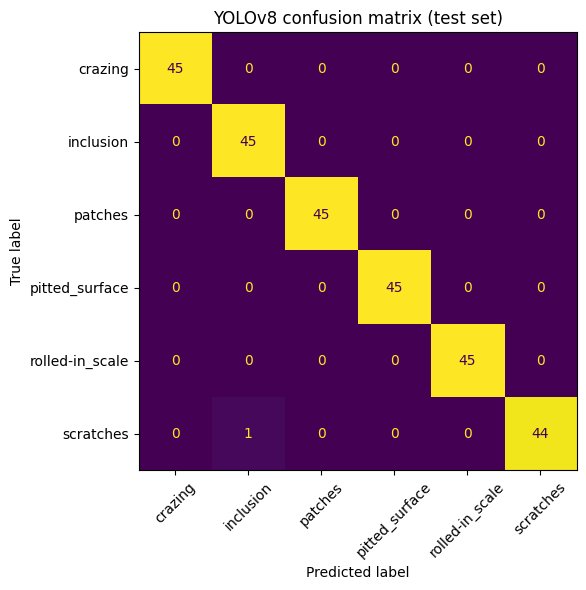

In [10]:
best = YOLO(best_path)
names = best.names
test_paths = test_df["path"].tolist()
# warm-up, then time the prediction
best.predict(test_paths[:4], imgsz=224, verbose=False)
t0 = time.time()
results = best.predict(test_paths, imgsz=224, verbose=False)
yolo_ms = (time.time() - t0) / len(test_paths) * 1000
yolo_pred = np.array([names[r.probs.top1] for r in results])
yolo_conf = np.array([float(r.probs.top1conf) for r in results])

y_true = test_df["label"].values
yolo_acc = accuracy_score(y_true, yolo_pred)
yolo_f1 = f1_score(y_true, yolo_pred, average="macro")
print(f"YOLOv8 accuracy: {yolo_acc:.3f} | macro F1: {yolo_f1:.3f} | {yolo_ms:.1f} ms/image (~{1000/yolo_ms:.0f} FPS)")
print(classification_report(y_true, yolo_pred, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_true, yolo_pred, xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title("YOLOv8 confusion matrix (test set)"); plt.tight_layout(); plt.show()

## 9. Compare both methods

In [11]:
comparison = pd.DataFrame({
    "Method": ["OpenCV features + Random Forest", "YOLOv8n-cls"],
    "Accuracy": [rf_acc, yolo_acc],
    "Macro F1": [rf_f1, yolo_f1],
    "ms / image": [rf_ms, yolo_ms],
}).round(3)
comparison

,Method,Accuracy,Macro F1,ms / image
0,OpenCV features + Random Forest,0.978,0.978,0.360
1,YOLOv8n-cls,0.996,0.996,2.667


In [12]:
# Per-class recall and most confused pairs (Pandas analysis of defect patterns)
rec = pd.DataFrame({"class": classes})
def recall_by_class(y, p):
    return {c: float(((y == c) & (p == c)).sum() / max((y == c).sum(), 1)) for c in classes}
rec["RF recall"] = rec["class"].map(recall_by_class(y_true, rf_pred))
rec["YOLO recall"] = rec["class"].map(recall_by_class(y_true, yolo_pred))
print(rec.round(3).to_string(index=False))

errs = pd.DataFrame({"true": y_true, "pred": yolo_pred})
errs = errs[errs.true != errs.pred]
print("\nMost confused pairs (YOLO):")
print(errs.value_counts().head(5))

          class  RF recall  YOLO recall
        crazing      0.978        1.000
      inclusion      1.000        1.000
        patches      0.978        1.000
 pitted_surface      1.000        1.000
rolled-in_scale      1.000        1.000
      scratches      0.911        0.978

Most confused pairs (YOLO):
true       pred     
scratches  inclusion    1
Name: count, dtype: int64


## 10. Failure cases (look at what the model gets wrong)

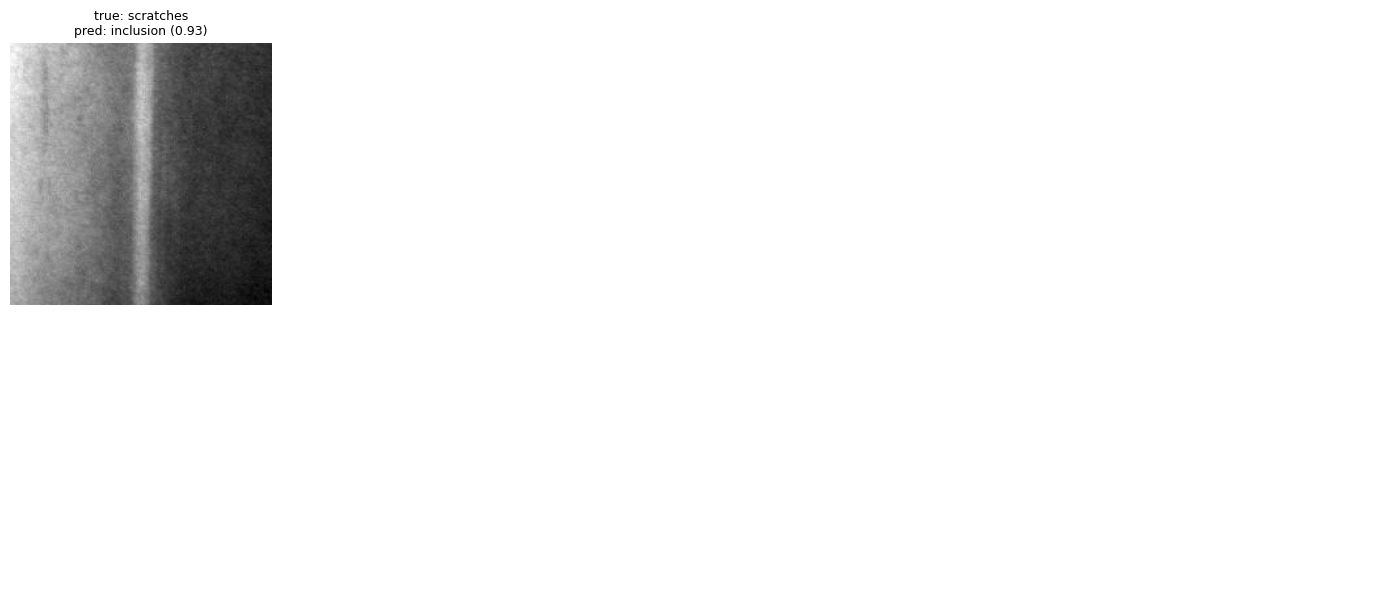

In [13]:
wrong = np.where(yolo_pred != y_true)[0][:10]
if len(wrong) == 0:
    print("No errors on the test set.")
else:
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(cv2.imread(test_paths[i], 0), cmap="gray")
        ax.set_title(f"true: {y_true[i]}\npred: {yolo_pred[i]} ({yolo_conf[i]:.2f})", fontsize=9)
    plt.tight_layout(); plt.show()

## 11. Save results and download

In [14]:
os.makedirs(f"{WORK}/results", exist_ok=True)
comparison.to_csv(f"{WORK}/results/comparison.csv", index=False)
rec.to_csv(f"{WORK}/results/per_class_recall.csv", index=False)
pd.DataFrame({"path": test_paths, "true": y_true, "yolo_pred": yolo_pred,
              "yolo_conf": yolo_conf, "rf_pred": rf_pred}).to_csv(f"{WORK}/results/test_predictions.csv", index=False)
shutil.copy(best_path, f"{WORK}/results/best.pt")
shutil.make_archive(f"{WORK}/neu_results", "zip", f"{WORK}/results")
from google.colab import files
files.download(f"{WORK}/neu_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Your numbers for the resume (use ONLY what is printed here)

In [15]:
print(f"Dataset: NEU Surface Defect Database, {len(df)} images, {len(classes)} defect classes")
print(f"Split: {len(train_df)} train / {len(val_df)} val / {len(test_df)} test")
print(f"OpenCV + Random Forest: accuracy {rf_acc:.1%}, macro F1 {rf_f1:.2f}")
print(f"YOLOv8n-cls: accuracy {yolo_acc:.1%}, macro F1 {yolo_f1:.2f}, {yolo_ms:.1f} ms/image")
print("Weakest class for YOLO:", rec.sort_values('YOLO recall').iloc[0]['class'])

Dataset: NEU Surface Defect Database, 1799 images, 6 defect classes
Split: 1259 train / 270 val / 270 test
OpenCV + Random Forest: accuracy 97.8%, macro F1 0.98
YOLOv8n-cls: accuracy 99.6%, macro F1 1.00, 2.7 ms/image
Weakest class for YOLO: scratches
